Saving 133883886687166516.jpg to 133883886687166516.jpg


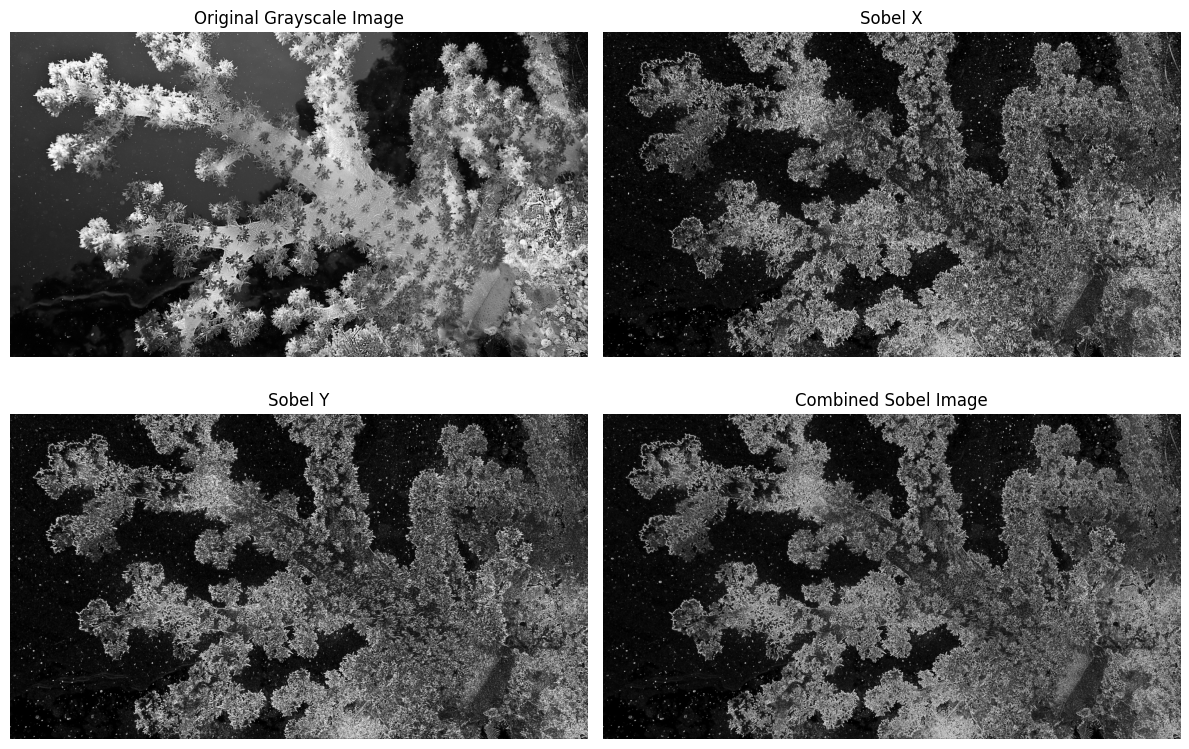

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

# Upload an image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read the image
img = cv2.imread(filename)

if img is None:
    print("Error: Image not found!")
else:
    # Convert image to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Apply Sobel filter in X direction
    sobel_x = cv2.Sobel(
        gray, cv2.CV_64F, 1, 0, ksize=3
    )

    # Apply Sobel filter in Y direction
    sobel_y = cv2.Sobel(
        gray, cv2.CV_64F, 0, 1, ksize=3
    )

    # Convert results to 8-bit images
    sobel_x = cv2.convertScaleAbs(sobel_x)
    sobel_y = cv2.convertScaleAbs(sobel_y)

    # Combine both directions
    sobel_combined = cv2.addWeighted(
        sobel_x, 0.5, sobel_y, 0.5, 0
    )

    # Display the images
    plt.figure(figsize=(12, 8))

    plt.subplot(2, 2, 1)
    plt.imshow(gray, cmap="gray")
    plt.title("Original Grayscale Image")
    plt.axis("off")

    plt.subplot(2, 2, 2)
    plt.imshow(sobel_x, cmap="gray")
    plt.title("Sobel X")
    plt.axis("off")

    plt.subplot(2, 2, 3)
    plt.imshow(sobel_y, cmap="gray")
    plt.title("Sobel Y")
    plt.axis("off")

    plt.subplot(2, 2, 4)
    plt.imshow(sobel_combined, cmap="gray")
    plt.title("Combined Sobel Image")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # Save the output image
    cv2.imwrite("sobel_output.jpg", sobel_combined)

    # Download the output
    files.download("sobel_output.jpg")